In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Ensure project root is in path
PROJECT_ROOT = Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from config.settings import (
    PROJECT_NAME,
    TARGET_COLUMN,
    TARGET_CLASSES,
    FEATURE_NAMES,
    FEATURE_DESCRIPTIONS,
    get_raw_dataset_path,
)
from src.data.eda_analyzer import (
    compute_dataset_summary,
    compute_data_quality_report,
    compute_class_distribution,
    compute_descriptive_statistics,
    compute_outlier_report,
    compute_correlation_analysis,
    compute_class_wise_statistics,
    compute_feature_variability_and_tests,
    compute_exploratory_pca,
)

# Configure default plotting parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
print('Environment and libraries initialized successfully.')

Environment and libraries initialized successfully.


In [2]:
dataset_path = get_raw_dataset_path()
print(f'Loading raw dataset from: {dataset_path}')
df = pd.read_excel(dataset_path)
print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Target Column Present: {TARGET_COLUMN in df.columns}')
df.head(10)

Loading raw dataset from: C:\Users\A.VARUN KUMAR REDDY\OneDrive\Desktop\AGRO\DryBeanDataset\Dry_Bean_Dataset.xlsx


Dataset Dimensions: 13611 rows, 17 columns
Target Column Present: True


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
5,30279,634.927,212.560556,181.510182,1.171067,0.520401,30600,196.347702,0.775688,0.989510,0.943852,0.923726,0.007020,0.003153,0.853270,0.999236,SEKER
6,30477,670.033,211.050155,184.039050,1.146768,0.489478,30970,196.988633,0.762402,0.984081,0.853080,0.933374,0.006925,0.003242,0.871186,0.999049,SEKER
7,30519,629.727,212.996755,182.737204,1.165591,0.513760,30847,197.124320,0.770682,0.989367,0.967109,0.925480,0.006979,0.003158,0.856514,0.998345,SEKER
8,30685,635.681,213.534145,183.157146,1.165852,0.514081,31044,197.659696,0.771561,0.988436,0.954240,0.925658,0.006959,0.003152,0.856844,0.998953,SEKER
9,30834,631.934,217.227813,180.897469,1.200834,0.553642,31120,198.139012,0.783683,0.990810,0.970278,0.912125,0.007045,0.003008,0.831973,0.999061,SEKER


In [3]:
print('Last 5 records:')
display(df.tail(5))

print('Random sample of 5 records (reproducible seed 42):')
display(df.sample(5, random_state=42))

Last 5 records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


Random sample of 5 records (reproducible seed 42):


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1488,42339,741.226,260.199331,207.306394,1.255144,0.604347,42676,232.180294,0.771202,0.992103,0.968387,0.892317,0.006146,0.002403,0.796230,0.999383,SEKER
2611,68247,1088.754,370.368146,237.863792,1.557060,0.766507,70172,294.779204,0.767683,0.972567,0.723492,0.795909,0.005427,0.001343,0.633471,0.986352,BARBUNYA
749,37856,708.716,248.430330,194.360324,1.278195,0.622835,38232,219.544429,0.744640,0.990165,0.947109,0.883726,0.006563,0.002469,0.780972,0.998235,SEKER
99,33143,648.385,222.526310,189.737379,1.172812,0.522480,33377,205.423899,0.769980,0.992989,0.990685,0.923144,0.006714,0.003008,0.852195,0.999465,SEKER
11298,29925,647.570,237.714031,161.004848,1.476440,0.735703,30321,195.196551,0.785309,0.986940,0.896748,0.821140,0.007944,0.002228,0.674271,0.995521,DERMASON


In [4]:
summary_df = compute_dataset_summary(df)
display(summary_df)

,Column Name,Data Type,Non-Null Count,Missing Count,Missing Pct,Unique Count,Memory Usage (KB)
0,Area,int64,13611,0,0.0,12011,106.46
1,Perimeter,float64,13611,0,0.0,13416,106.46
2,MajorAxisLength,float64,13611,0,0.0,13543,106.46
3,MinorAxisLength,float64,13611,0,0.0,13543,106.46
4,AspectRation,float64,13611,0,0.0,13543,106.46
5,Eccentricity,float64,13611,0,0.0,13543,106.46
6,ConvexArea,int64,13611,0,0.0,12066,106.46
7,EquivDiameter,float64,13611,0,0.0,12011,106.46
8,Extent,float64,13611,0,0.0,13535,106.46
9,Solidity,float64,13611,0,0.0,13526,106.46


In [5]:
print('Dataset Memory and Dtype Overview:')
df.info()

Dataset Memory and Dtype Overview:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  s

In [6]:
quality_dict = compute_data_quality_report(df)
print('--- DATA QUALITY AUDIT RESULTS ---')
print(f'Total observations: {quality_dict["total_records"]:,}')
print(f'Total input features: {quality_dict["total_features"]}')
print(f'Total missing cells: {quality_dict["total_missing_cells"]} ({quality_dict["missing_percentage"]}%)')
print(f'Exact duplicate records: {quality_dict["exact_duplicates"]} ({quality_dict["duplicate_percentage"]}%)')
print(f'Unique records: {quality_dict["unique_records"]:,}')
print(f'Constant features: {quality_dict["constant_features"]}')
print(f'Low variance features: {quality_dict["low_variance_features"]}')
print(f'Negative numerical values: {sum(quality_dict["negative_values_per_col"].values())}')
print(f'Zero values in features: {sum(quality_dict["zero_values_per_col"].values())}')
print(f'Infinite values in features: {sum(quality_dict["infinite_values_per_col"].values())}')

--- DATA QUALITY AUDIT RESULTS ---
Total observations: 13,611
Total input features: 16
Total missing cells: 0 (0.0%)
Exact duplicate records: 68 (0.4996%)
Unique records: 13,543
Constant features: []
Low variance features: ['Solidity', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor4']
Negative numerical values: 0
Zero values in features: 0
Infinite values in features: 0


,Class,Sample Count,Percentage,Ratio to Majority (1:N)
0,DERMASON,3546,26.05,1.00
1,SIRA,2636,19.37,1.35
2,SEKER,2027,14.89,1.75
3,HOROZ,1928,14.17,1.84
4,CALI,1630,11.98,2.18
5,BARBUNYA,1322,9.71,2.68
6,BOMBAY,522,3.84,6.79


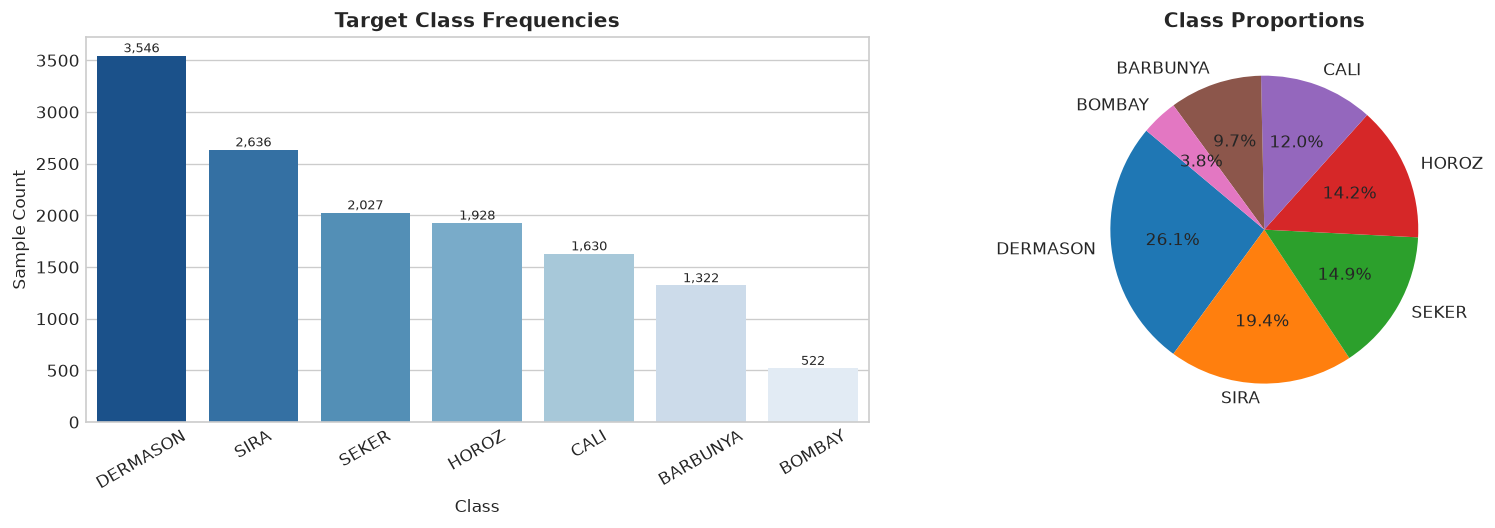

In [7]:
class_df = compute_class_distribution(df)
display(class_df)

# Class distribution plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=class_df, x='Class', y='Sample Count', ax=ax1, palette='Blues_r')
ax1.set_title('Target Class Frequencies', fontweight='bold')
ax1.set_ylabel('Sample Count')
ax1.tick_params(axis='x', rotation=30)
for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f'{int(h):,}', (p.get_x() + p.get_width() / 2., h), ha='center', va='bottom', fontsize=8)

ax2.pie(class_df['Sample Count'], labels=class_df['Class'], autopct='%1.1f%%', startangle=140,
        colors=sns.color_palette('tab10', 7))
ax2.set_title('Class Proportions', fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
stats_df = compute_descriptive_statistics(df)
display(stats_df)

,Feature,Count,Mean,Std Dev,Variance,Median,Mode,Min,P10,Q1 (P25),Q2 (Median),Q3 (P75),P90,Max,Range,IQR,Skewness,Kurtosis,CV
0,Area,13611,53048.2845,29324.0957,8.599026e+08,44652.0000,28122.0000,20420.0000,30391.0000,36328.0000,44652.0000,61332.0000,78114.0000,254616.0000,234196.0000,25004.0000,2.9529,10.8008,0.5528
1,Perimeter,13611,855.2835,214.2897,4.592007e+04,794.9410,683.3410,524.7360,647.0930,703.5235,794.9410,977.2130,1093.8580,1985.3700,1460.6340,273.6895,1.6261,3.5881,0.2505
2,MajorAxisLength,13611,320.1419,85.6942,7.343493e+03,296.8834,277.3685,183.6012,233.5736,253.3036,296.8834,376.4950,416.8629,738.8602,555.2590,123.1914,1.3578,2.5319,0.2677
3,MinorAxisLength,13611,202.2707,44.9701,2.022309e+03,192.4317,154.3056,122.5127,160.5980,175.8482,192.4317,217.0317,246.6858,460.1985,337.6858,41.1836,2.2382,6.6511,0.2223
4,AspectRation,13611,1.5832,0.2467,6.090000e-02,1.5511,1.6971,1.0249,1.2649,1.4323,1.5511,1.7071,1.9677,2.4303,1.4054,0.2748,0.5826,0.1138,0.1558
5,Eccentricity,13611,0.7509,0.0920,8.500000e-03,0.7644,0.8080,0.2190,0.6123,0.7159,0.7644,0.8105,0.8612,0.9114,0.6925,0.0945,-1.0628,1.3875,0.1225
6,ConvexArea,13611,53768.2002,29774.9158,8.865456e+08,45178.0000,37023.0000,20684.0000,30730.0000,36714.5000,45178.0000,62294.0000,79400.0000,263261.0000,242577.0000,25579.5000,2.9418,10.7436,0.5538
7,EquivDiameter,13611,253.0642,59.1771,3.501932e+03,238.4380,189.2248,161.2438,196.7105,215.0680,238.4380,279.4465,315.3694,569.3744,408.1306,64.3785,1.9490,5.1921,0.2338
8,Extent,13611,0.7497,0.0491,2.400000e-03,0.7599,0.5910,0.5553,0.6864,0.7186,0.7599,0.7869,0.8036,0.8662,0.3109,0.0682,-0.8953,0.6433,0.0655
9,Solidity,13611,0.9871,0.0047,0.000000e+00,0.9883,0.9566,0.9192,0.9817,0.9857,0.9883,0.9900,0.9914,0.9947,0.0754,0.0043,-2.5501,12.7996,0.0047


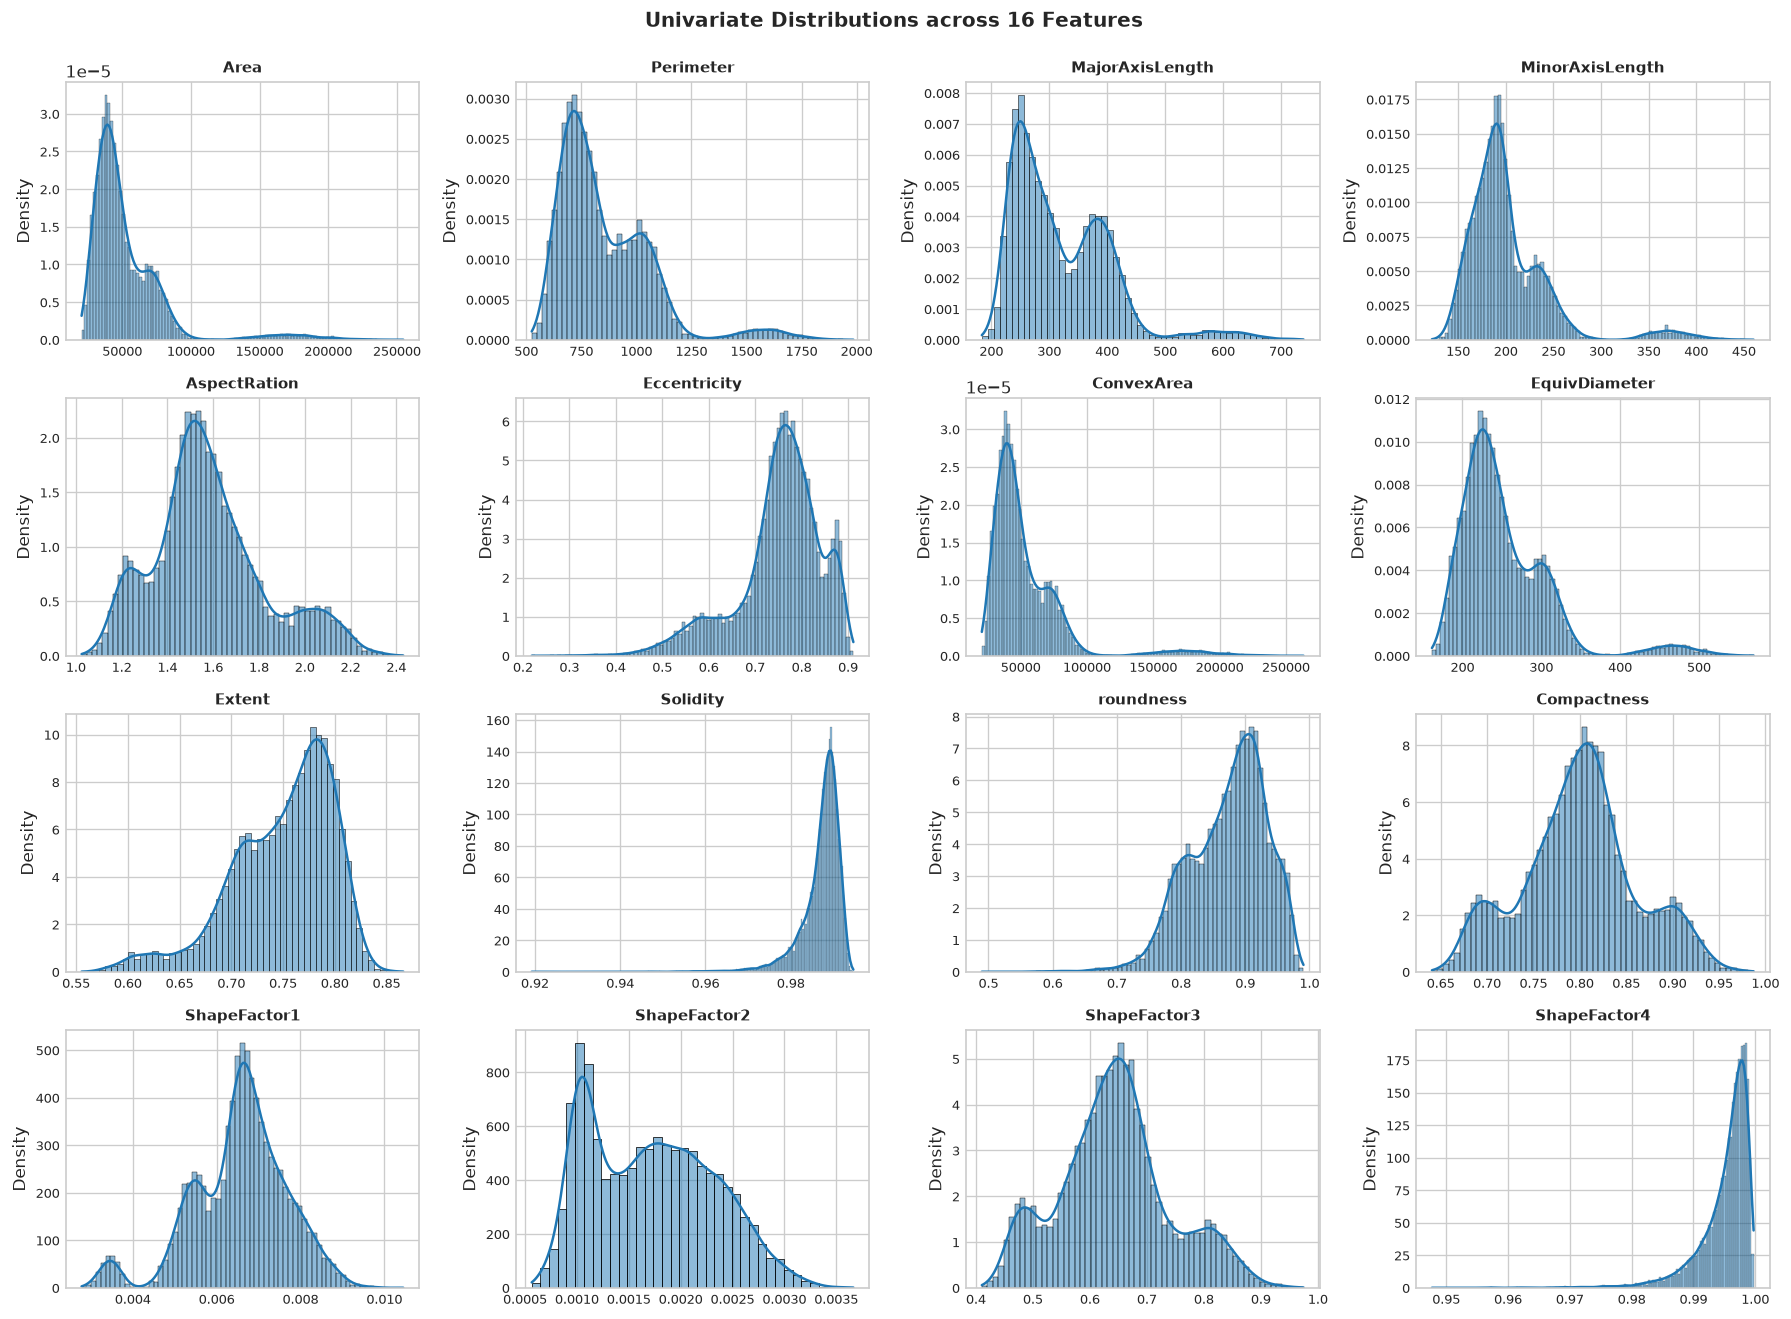

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.flatten()
for idx, feat in enumerate(FEATURE_NAMES):
    sns.histplot(df[feat], kde=True, ax=axes[idx], color='#1f77b4', stat='density', alpha=0.5)
    axes[idx].set_title(feat, fontsize=9, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].tick_params(labelsize=8)
plt.suptitle('Univariate Distributions across 16 Features', fontsize=12, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

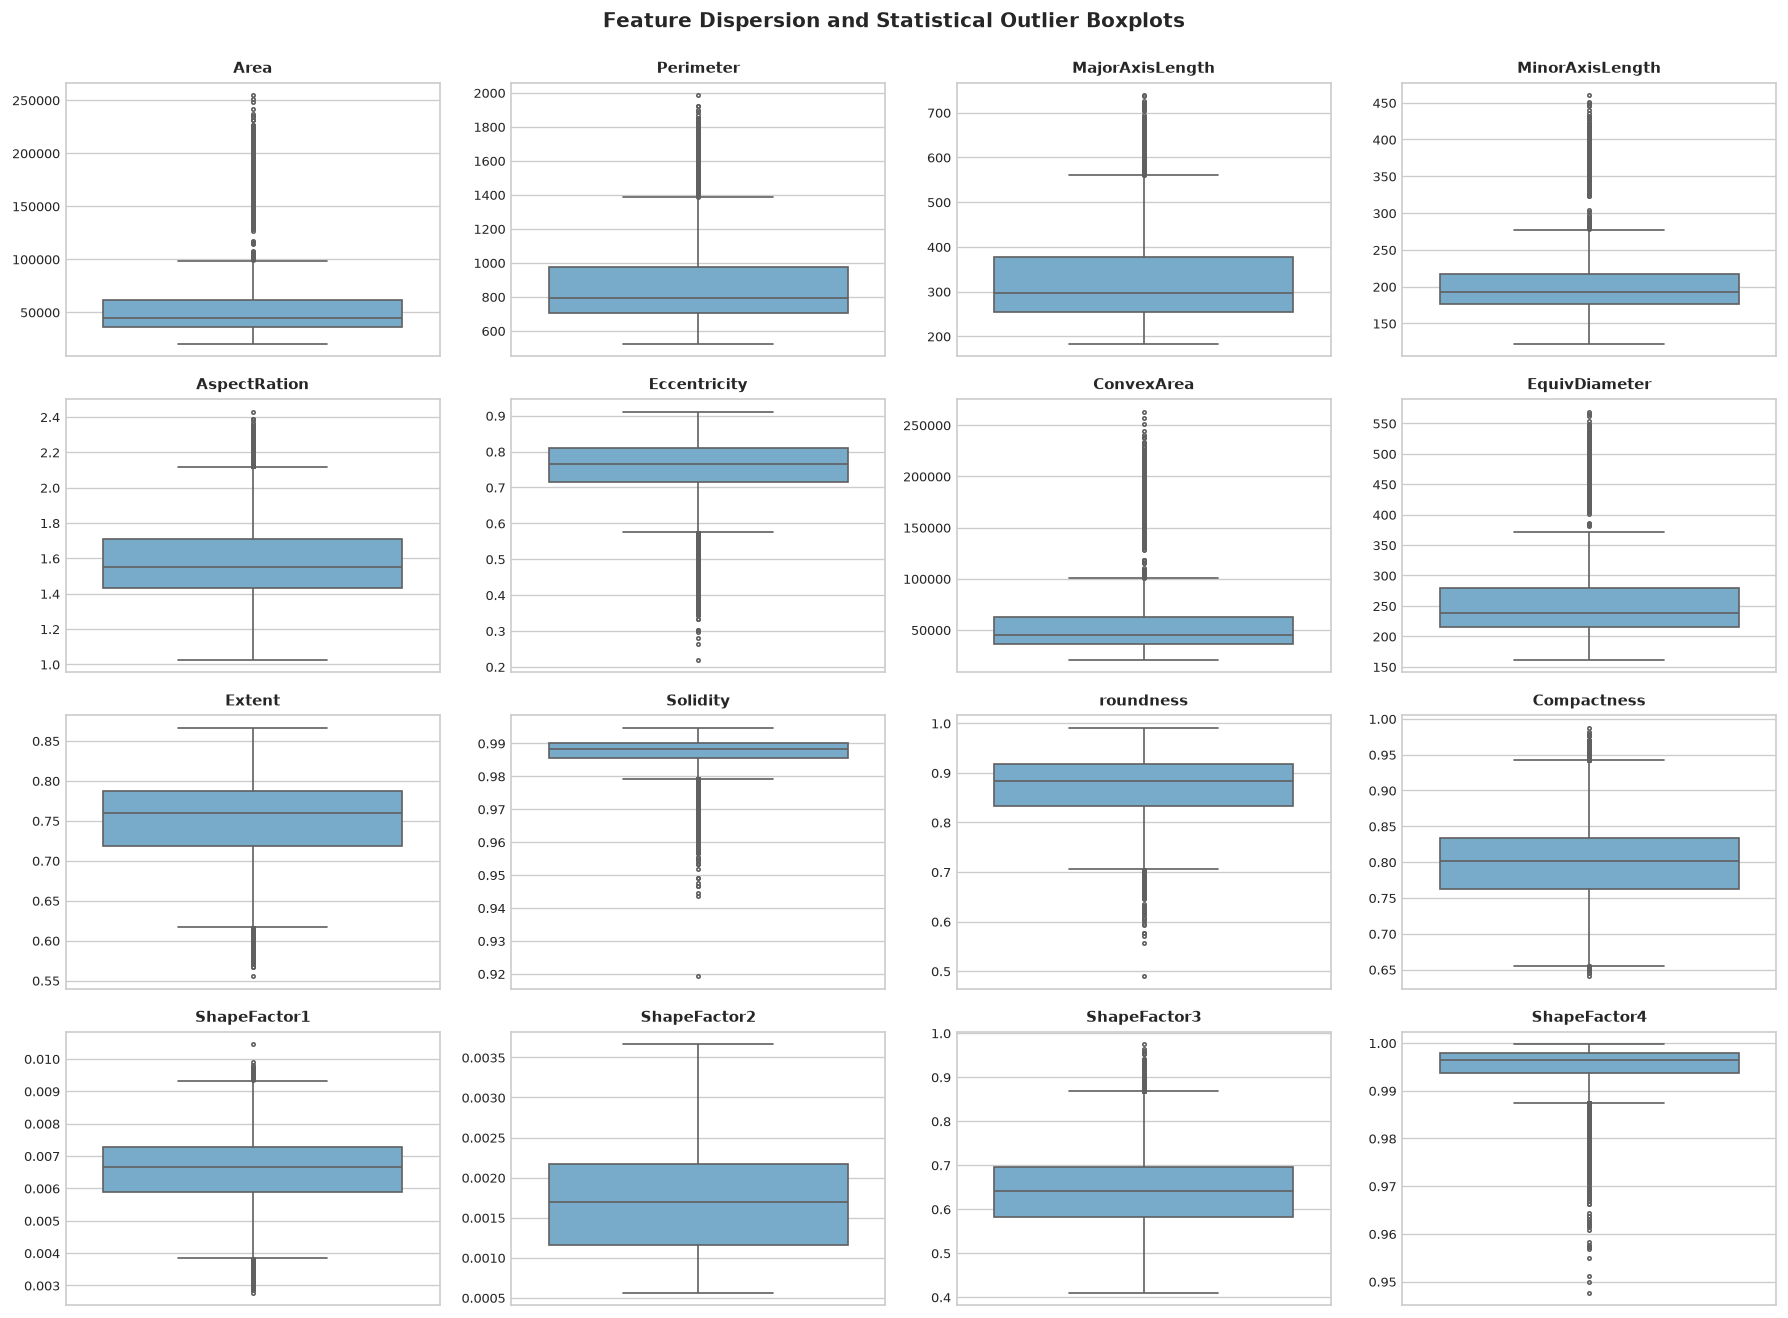

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
axes = axes.flatten()
for idx, feat in enumerate(FEATURE_NAMES):
    sns.boxplot(y=df[feat], ax=axes[idx], color='#6baed6', fliersize=2)
    axes[idx].set_title(feat, fontsize=9, fontweight='bold')
    axes[idx].set_ylabel('')
    axes[idx].tick_params(labelsize=8)
plt.suptitle('Feature Dispersion and Statistical Outlier Boxplots', fontsize=12, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

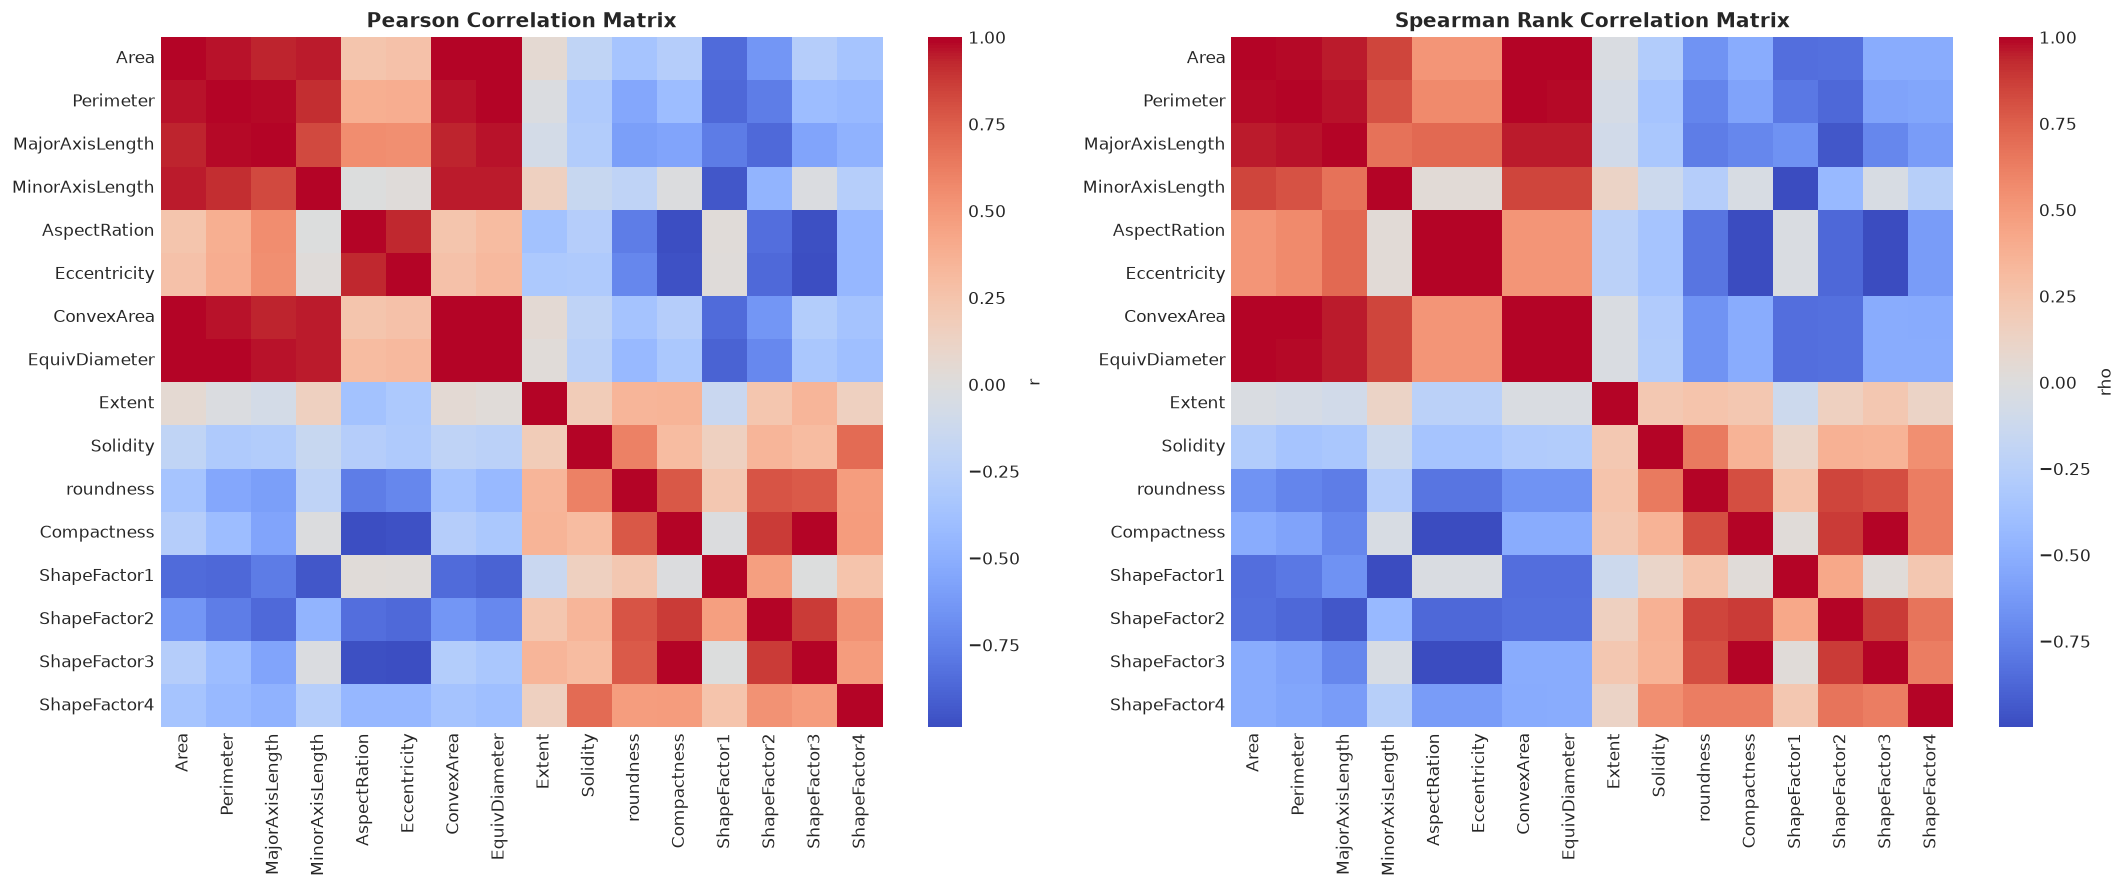

Top Strong Positive Correlations (|r| >= 0.80):


,Feature 1,Feature 2,Pearson r,Spearman rho
3,Area,ConvexArea,0.9999,0.9999
17,Compactness,ShapeFactor3,0.9987,1.0000
8,Perimeter,EquivDiameter,0.9914,0.9916
15,ConvexArea,EquivDiameter,0.9852,0.9999
4,Area,EquivDiameter,0.9850,1.0000
5,Perimeter,MajorAxisLength,0.9773,0.9714
7,Perimeter,ConvexArea,0.9677,0.9925
0,Area,Perimeter,0.9667,0.9916


Top Strong Negative Correlations (|r| <= -0.80):


,Feature 1,Feature 2,Pearson r,Spearman rho
4,AspectRation,Compactness,-0.9877,-0.9997
9,Eccentricity,ShapeFactor3,-0.9811,-0.9997
6,AspectRation,ShapeFactor3,-0.9786,-0.9997
7,Eccentricity,Compactness,-0.9703,-0.9997
3,MinorAxisLength,ShapeFactor1,-0.9472,-0.9995
11,EquivDiameter,ShapeFactor1,-0.8927,-0.8430
1,Perimeter,ShapeFactor1,-0.8646,-0.7953
8,Eccentricity,ShapeFactor2,-0.8601,-0.8721


In [11]:
corr_results = compute_correlation_analysis(df, threshold=0.80)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7.5))
sns.heatmap(corr_results['pearson_matrix'], cmap='coolwarm', center=0, ax=ax1, cbar_kws={'label': 'r'})
ax1.set_title('Pearson Correlation Matrix', fontweight='bold')
sns.heatmap(corr_results['spearman_matrix'], cmap='coolwarm', center=0, ax=ax2, cbar_kws={'label': 'rho'})
ax2.set_title('Spearman Rank Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

print('Top Strong Positive Correlations (|r| >= 0.80):')
display(corr_results['strong_positive_df'].head(8))

print('Top Strong Negative Correlations (|r| <= -0.80):')
display(corr_results['strong_negative_df'].head(8))

**Observation on Multicollinearity:**  
There is extreme collinearity among dimensional attributes:
- `Area` and `ConvexArea`: $r = 1.00$
- `Area` and `EquivDiameter`: $r = 0.99$
- `Perimeter` and `MajorAxisLength`: $r = 0.98$
- `AspectRation` and `Eccentricity`: $r = 0.92$
Tree-based models (such as Random Forest and XGBoost) handle collinearity naturally, whereas linear models will benefit from regularization or dimensionality reduction.

In [12]:
outlier_df = compute_outlier_report(df)
display(outlier_df)

,Feature,IQR Lower Bound,IQR Upper Bound,IQR Outlier Count,IQR Outlier Pct,Z-Score (|z|>3) Count,Z-Score Outlier Pct
0,Area,-1178.0000,98838.0000,551,4.05,483,3.55
1,Perimeter,292.9892,1387.7473,500,3.67,404,2.97
2,MajorAxisLength,68.5166,561.2821,379,2.78,316,2.32
3,MinorAxisLength,114.0728,278.8071,569,4.18,508,3.73
4,AspectRation,1.0201,2.1193,473,3.48,15,0.11
5,Eccentricity,0.5741,0.9523,843,6.19,125,0.92
6,ConvexArea,-1654.7500,100663.2500,550,4.04,483,3.55
7,EquivDiameter,118.5003,376.0142,526,3.86,465,3.42
8,Extent,0.6163,0.8892,275,2.02,135,0.99
9,Solidity,0.9792,0.9965,778,5.72,238,1.75


In [13]:
var_df, tests_df = compute_feature_variability_and_tests(df)
print('Hypothesis Testing Results (ANOVA & Kruskal-Wallis):')
display(tests_df)

print('Feature Variance Decomposition (Between vs Within Class):')
display(var_df)

Hypothesis Testing Results (ANOVA & Kruskal-Wallis):


,Feature,ANOVA F-Statistic,ANOVA p-value,ANOVA p-adj (Bonferroni),Kruskal-Wallis H,KW p-value,KW p-adj (Bonferroni),Statistically Significant (p < 0.001)
0,Area,29017.5105,0.0,0.0,11730.1527,0.000000e+00,0.000000e+00,True
6,ConvexArea,28961.7912,0.0,0.0,11750.9122,0.000000e+00,0.000000e+00,True
7,EquivDiameter,25444.5478,0.0,0.0,11730.1527,0.000000e+00,0.000000e+00,True
1,Perimeter,24283.6637,0.0,0.0,11891.0677,0.000000e+00,0.000000e+00,True
3,MinorAxisLength,22442.3864,0.0,0.0,11130.0325,0.000000e+00,0.000000e+00,True
2,MajorAxisLength,21622.2379,0.0,0.0,11678.7152,0.000000e+00,0.000000e+00,True
13,ShapeFactor2,12329.8839,0.0,0.0,11779.0934,0.000000e+00,0.000000e+00,True
12,ShapeFactor1,12081.3211,0.0,0.0,11158.8985,0.000000e+00,0.000000e+00,True
4,AspectRation,10376.9792,0.0,0.0,10184.7225,0.000000e+00,0.000000e+00,True
11,Compactness,10166.1179,0.0,0.0,10264.8891,0.000000e+00,0.000000e+00,True


Feature Variance Decomposition (Between vs Within Class):


,Feature,Total Variance,Between-Class Variance (MSB),Within-Class Variance (MSW),F-Ratio (MSB/MSW),Eta-Squared (Variance Explained)
0,Area,8.599026e+08,1.809182e+12,6.234794e+07,29017.5105,0.9275
6,ConvexArea,8.865456e+08,1.864977e+12,6.439441e+07,28961.7912,0.9274
7,EquivDiameter,3.501932e+03,7.293622e+06,2.866477e+02,25444.5478,0.9182
1,Perimeter,4.592007e+04,9.526707e+07,3.923093e+03,24283.6637,0.9146
3,MinorAxisLength,2.022309e+03,4.166349e+06,1.856464e+02,22442.3864,0.9082
2,MajorAxisLength,7.343493e+03,1.507655e+07,6.972704e+02,21622.2379,0.9051
13,ShapeFactor2,0.000000e+00,7.000000e-04,0.000000e+00,12329.8839,0.8447
12,ShapeFactor1,0.000000e+00,2.400000e-03,0.000000e+00,12081.3211,0.8420
4,AspectRation,6.090000e-02,1.132779e+02,1.090000e-02,10376.9792,0.8207
11,Compactness,3.800000e-03,7.063700e+00,7.000000e-04,10166.1179,0.8176


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.5547,0.5547
1,PC2,0.2643,0.8190
2,PC3,0.0801,0.8990
3,PC4,0.0511,0.9502
4,PC5,0.0274,0.9776


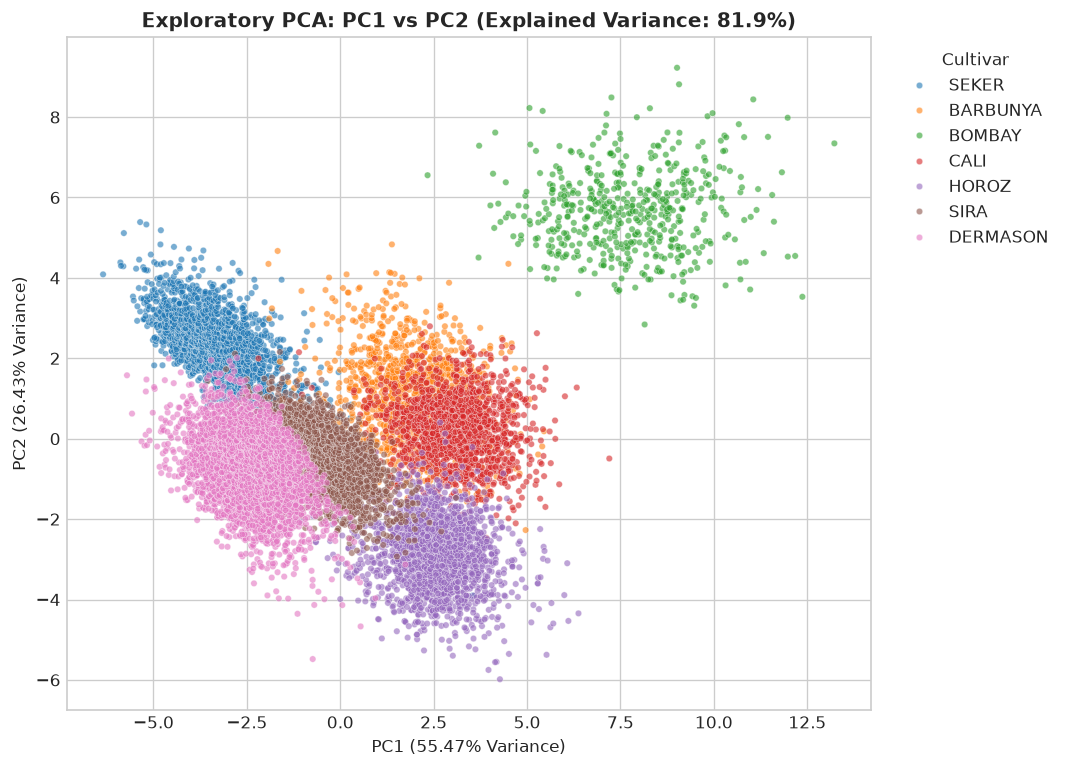

In [14]:
pca_res = compute_exploratory_pca(df, n_components=5)
display(pca_res['pca_summary_df'])

fig, ax = plt.subplots(figsize=(9, 6.5))
pca_df = pd.DataFrame({
    'PC1': pca_res['X_pca_2d'][:, 0],
    'PC2': pca_res['X_pca_2d'][:, 1],
    'Class': df[TARGET_COLUMN].values
})
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Class', palette='tab10', alpha=0.6, s=15, ax=ax)
ax.set_title(f'Exploratory PCA: PC1 vs PC2 (Explained Variance: {pca_res["var_pc1"] + pca_res["var_pc2"]:.1f}%)', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca_res["var_pc1"]}% Variance)')
ax.set_ylabel(f'PC2 ({pca_res["var_pc2"]}% Variance)')
ax.legend(title='Cultivar', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()